# Notebook 5 of 5: Recipes, specs, yield, and the fab-tool app

**Goal:** see how the simulations from notebooks 1 to 4 become a *virtual deposition tool*: recommended recipes
(**POR**), pass/fail limits (**specs**), the fraction of single wafers that pass (**yield**), and the Streamlit app
that records a run and replays it in the browser.

## How to use this notebook

| | |
|---|---|
| **Prerequisites** | Notebooks 3 and 4 (temperature, flux, hops, roughness `W`, voids, step coverage, process windows). |
| **Kernel** | *Thin Film Growth* (`thin-film-growth`, the project's `.venv`). |
| **Run order** | Top to bottom. Notebook 5 of 5 (`01` → `02` → `03` → `04` → `05`). |
| **Runtime** | About half a minute (Part 6 re-simulates 5 wafers of each of the 6 recipes in the yield study). |
| **Files written** | **None in the project.** Only reads `results/`. Part 8 can optionally write a replay page to your system's temporary folder (off by default). |

Files to keep open: `src/thin_film/ideal.py`, `src/thin_film/fab.py`, `src/thin_film/recording.py`,
`scripts/run_por_yield.py`, `app/streamlit_app.py`, `app/player.py`.

## Table of contents
1. Setup and module map
2. Fab vocabulary in plain words
3. The POR recipes (`ideal.py`)
4. Fab helpers and specs (`fab.py`)
5. Recording a wafer for replay (`recording.py`)
6. Yield: judging single wafers (`scripts/run_por_yield.py`, `results/por_yield/`)
7. How the yield study's numbers compare with the code comments
8. The app: from sidebar to browser player
9. Recap and exercises

## 1. Setup and module map

In [1]:
# Setup: works locally (run from notebooks/ or the project root) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")   # we only READ from here, never write
print("project root:", ROOT)

project root: <project-root>


| File | What we use | Role |
|---|---|---|
| `src/thin_film/ideal.py` | `IDEAL` | the POR per model, with the evidence |
| `src/thin_film/fab.py` | `ML_NM`, `MODULES`, `SPECS`, `kelvin_to_celsius`, `rate_nm_per_min`, `thickness_nm`, `recipe_name`, `wafer_id`, `spec_check` | fab vocabulary and pass/fail rules |
| `src/thin_film/recording.py` | `record_1d`, `record_trench`, `trench_frame`, `final_metrics` | record a run as compact frames |
| `scripts/run_por_yield.py` | its `RECIPES`, `N_SEEDS`, `N_FRAMES` and loop (repeated here, not run) | single-wafer pass rates |
| `app/player.py` | `wafer_payload`, `build_html` | pack recordings into the player page |
| `app/fab_player.html` | (template) | the in-browser replay (JavaScript) |
| `app/streamlit_app.py` | (read, not run) | the app: sidebar, run/compare, lot history |

In [2]:
import base64, json, tempfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thin_film import fab
from thin_film import trench as tr
from thin_film.ideal import IDEAL
from thin_film.recording import record_1d, record_trench, trench_frame, final_metrics
from thin_film.units import thermal_parameters
from thin_film.plotting import trench_image, TRENCH_CMAP   # white empty, grey substrate, blue film, red void

sys.path.insert(0, os.path.join(ROOT, "app"))      # app/player.py is a plain module next to the app
import player

## 2. Fab vocabulary in plain words

A chip factory is a **fab**. The words below appear in the app and in `fab.py`:

| Word | Meaning here |
|---|---|
| **wafer** | one simulated film (one run with one seed) |
| **lot** | a batch of wafers (the app uses lot `TF-0001`; wafers are `TF-0001-W01`, `W02`, ...) |
| **process module (PM)** | one chamber of the tool; here one model: PM1 random deposition, PM2 surface relaxation, PM3 thermal hopping, PM4 trench fill |
| **recipe** | the settings for a run: temperature, deposition rate, thickness, trench size |
| **POR** (process of record) | the approved default recipe |
| **spec** | a pass/fail limit applied to **each** wafer |
| **yield** | the fraction of wafers that pass their spec |
| **Rq** | metrology (measurement) name for RMS roughness: exactly the `W` of notebooks 1 to 3 |
| **in-situ / SEM / AFM** | views in the app: the film as it grows, a drawing styled like a scanning-electron-microscope cross-section, and a top-down height strip (atomic force microscope); all are renderings of the simulation, not microscope data |

Analogy: a bakery. The POR is the house recipe; the spec is "each cake must rise at least 5 cm"; yield is the share
of cakes that pass. A recipe can be fine *on average* and still produce some flat cakes.

## 3. The POR recipes (`ideal.py`)

`IDEAL` holds one entry per model: the settings, the reasoning (`why`) and where the evidence lives (`source`).
"Ideal" means different things per model: for random deposition and surface relaxation there is nothing to tune, so
the settings simply show the physics best; for thermal hopping it is the smoothest film; for the trench, void-free
filling with high step coverage.

In [3]:
pd.set_option("display.max_colwidth", 200)
pd.DataFrame([{"model": k, "settings": json.dumps(v["settings"]), "source": v["source"]} for k, v in IDEAL.items()])

,model,settings,source
0,random_deposition,"{""n_columns"": 200, ""n_monolayers"": 1000}",results/phase1_random_deposition
1,surface_relaxation,"{""n_columns"": 100, ""n_monolayers"": 3000}",results/phase2_surface_relaxation
2,thermal,"{""temperature"": 375, ""flux"": 0.01, ""n_columns"": 200, ""n_monolayers"": 100}","results/phase3_process_window, results/por_yield"
3,trench,"{""temperature"": 420, ""flux"": 1.0, ""trench_width"": 16, ""trench_depth"": 16, ""n_monolayers"": 24}","results/phase4_process_window, results/por_yield"


In [4]:
for model in ("thermal", "trench"):
    print(f"{model}: {IDEAL[model]['why']}\n")

thermal: Smoothest film in the grid search (W = 0.91 after 50 ML vs 2.5 at 375 K / 1 ML/s). It is the coolest temperature at which slow deposition still maxes out the hops (1e4 per landing): atoms explore fully while bonds stay strong enough to hold them at good sites. All 30 test wafers passed the spec. Faster alternative: 450 K at 1 ML/s gives W = 1.35 at 100x the deposition rate, but only 24 of 30 wafers pass.

trench: Void-free in the grid search (void 0, coverage 0.59), within noise of the highest coverage found (0.60 at 520 K) but 100 K cooler. Single wafers vary: 24 of 30 seeds pass the spec (the rest have coverage just under 0.50 or a 1-6 cell void), so expect ~80% yield. Geometry matters most: a trench must be about as wide as it is deep. At width 8 / depth 16 no temperature or rate avoids a void. 460 K at 10 ML/s is also void-free on average and 10x faster, but only 16 of 30 wafers pass.



Notebooks 3 (Part 9) and 4 (Part 10) showed where the thermal and trench POR come from (the process-window grids).
The yield numbers quoted in the text (30/30, 24/30, 16/30) come from `results/por_yield`, Part 6 below.

## 4. Fab helpers and specs (`fab.py`)

Nothing in `fab.py` changes the physics; it translates simulation quantities into fab units and names. The lattice
has no real length scale, so the project assumes **1 ML ≈ 0.3 nm** (`ML_NM`), an illustrative choice.

In [5]:
print("ML_NM =", fab.ML_NM, "nm per monolayer")
print("420 K in Celsius          :", round(fab.kelvin_to_celsius(420), 2), "°C")
print("1 ML/s in nm/min          :", fab.rate_nm_per_min(1.0), "  (= 1 * 0.3 nm * 60 s)")
print("0.01 ML/s in nm/min       :", round(fab.rate_nm_per_min(0.01), 3))
print("24 ML film thickness      :", round(fab.thickness_nm(24), 2), "nm")
print("thermal POR recipe name   :", fab.recipe_name("thermal", 375, 0.01, 100))
print("trench POR recipe name    :", fab.recipe_name("trench", 420, 1.0, 24, (16, 16)))
print("third wafer of lot TF-0001:", fab.wafer_id("TF-0001", 3))
print("\nmodules:", json.dumps(fab.MODULES, indent=1, ensure_ascii=False))

ML_NM = 0.3 nm per monolayer
420 K in Celsius          : 146.85 °C
1 ML/s in nm/min          : 18.0   (= 1 * 0.3 nm * 60 s)
0.01 ML/s in nm/min       : 0.18
24 ML film thickness      : 7.2 nm
thermal POR recipe name   : PM3-TH-375K-0.01ML/s-100ML
trench POR recipe name    : PM4-TRF-420K-1ML/s-W16D16
third wafer of lot TF-0001: TF-0001-W03

modules: {
 "random_deposition": "PM1 · Random deposition (1D)",
 "surface_relaxation": "PM2 · Surface relaxation (1D)",
 "thermal": "PM3 · Thermal hopping (1D)",
 "trench": "PM4 · Trench fill (2D)"
}


### Specs

`SPECS` maps each module to its limits (`None` = monitor only: PM1 and PM2 have no knobs to tune, so their wafers are
marked `MONITOR`). `spec_check(module, metrics)` returns `PASS`, `FAIL` or `MONITOR`:

* PM3 (thermal): **Rq ≤ 2.0 atoms** for a 100 ML film;
* PM4 (trench): **trench void = 0 and step coverage ≥ 0.50**.

In [6]:
print(json.dumps(fab.SPECS, indent=1, ensure_ascii=False))
examples = [("thermal", {"rq": 1.9}), ("thermal", {"rq": 2.1}),
            ("trench", {"trench_void_area": 0, "step_coverage": 0.6}),
            ("trench", {"trench_void_area": 3, "step_coverage": 0.6}),
            ("trench", {"trench_void_area": 0, "step_coverage": 0.49}),
            ("random_deposition", {"rq": 9.0})]
for module, metrics in examples:
    print(f"{module:18s} {str(metrics):50s} -> {fab.spec_check(module, metrics)}")

{
 "random_deposition": null,
 "surface_relaxation": null,
 "thermal": {
  "rq_max": 2.0,
  "text": "Rq ≤ 2.0 atoms (100 ML film)"
 },
 "trench": {
  "void_max": 0,
  "coverage_min": 0.5,
  "text": "trench void = 0 and step coverage ≥ 0.50"
 }
}
thermal            {'rq': 1.9}                                        -> PASS
thermal            {'rq': 2.1}                                        -> FAIL
trench             {'trench_void_area': 0, 'step_coverage': 0.6}      -> PASS
trench             {'trench_void_area': 3, 'step_coverage': 0.6}      -> FAIL
trench             {'trench_void_area': 0, 'step_coverage': 0.49}     -> FAIL
random_deposition  {'rq': 9.0}                                        -> MONITOR


## 5. Recording a wafer for replay (`recording.py`)

The app first simulates the whole run, then replays it in the browser so you can pause and scrub. To keep the data
small, `recording.py` stores **frames**:

* **1D models** (`record_1d`): the full heights array after every frame, shape `(n_frames + 1, N)`; frame 0 is the
  bare substrate. Each frame deposits `per_frame = round(n_monolayers * N / n_frames)` atoms. For the thermal model
  it calls `thermal_grow` once per frame, with a new seed drawn from `np.random.default_rng(seed)`.
* **Trench** (`record_trench`): instead of one grid per frame, two small maps: `arrival[y, x]` = frame in which the
  cell became film, and `void_start[y, x]` = first frame in which it was a sealed void (255 = never). This works
  because only the newest atom moves (notebook 4), so a film cell stays film once a frame ends.

### A thermal POR wafer (PM3)

Exactly what the app does for PM3 with the POR loaded (200 columns, 100 ML, 60 frames, here seed 0):

recorded in 1.9 s
keys: ['kind', 'model', 'heights', 'monolayers', 'rq']
heights shape (frames + 1, columns): (61, 200)
atoms per frame: 333 | monolayers at last frame: 99.9
final metrics: {'rq': 1.2449899597988732, 'monolayers': 99.9} -> PASS


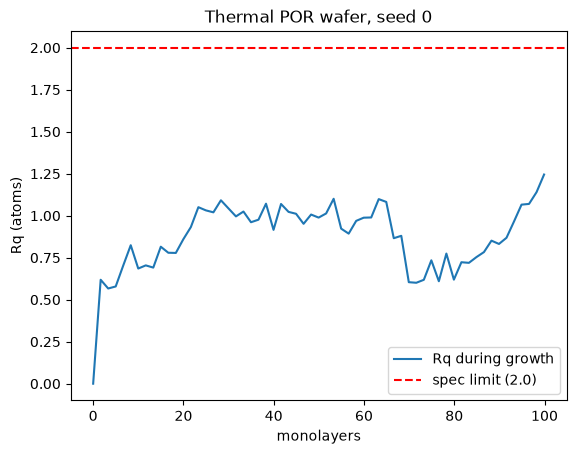

In [7]:
por_th = IDEAL["thermal"]["settings"]
eps, hops = thermal_parameters(por_th["temperature"], 0.2, 0.8, por_th["flux"], max_hops=1e4)
t0 = time.perf_counter()
rec = record_1d("thermal", 200, por_th["n_monolayers"], 60, seed=0, epsilon=eps, hops=hops)
print(f"recorded in {time.perf_counter() - t0:.1f} s")
print("keys:", list(rec))
print("heights shape (frames + 1, columns):", rec["heights"].shape)
print("atoms per frame:", int(rec["heights"][1].sum()), "| monolayers at last frame:", rec["monolayers"][-1])
m = final_metrics(rec)
print("final metrics:", m, "->", fab.spec_check("thermal", m))
plt.plot(rec["monolayers"], rec["rq"], label="Rq during growth")
plt.axhline(fab.SPECS["thermal"]["rq_max"], color="r", ls="--", label="spec limit (2.0)")
plt.xlabel("monolayers"); plt.ylabel("Rq (atoms)"); plt.legend(); plt.title("Thermal POR wafer, seed 0"); plt.show()

**What to notice:** the final Rq of this wafer, 1.24 in the saved yield table (`results/por_yield`, thermal POR,
seed 0), is reproduced here because the yield script calls the same `record_1d` with the same arguments. Also note
`per_frame = round(100 * 200 / 60) = 333` atoms, so the recorded film ends at 99.9 ML rather than exactly 100.

### A trench POR wafer (PM4) and rebuilding frames

`record_trench(settings, n_frames)` deposits `per_frame` atoms per frame using seed `settings.seed * 1000 + k` for
frame `k`, and after each frame records which cells became film and which became void. `trench_frame(rec, k)`
rebuilds the cell codes of any frame from the two maps:
film if `arrival <= k`; void if `void_start <= k < arrival`; substrate if it started as substrate; else empty.

map shape (cropped rows, columns): (50, 76) | dtype: uint8
final metrics: {'step_coverage': 0.519916142557652, 'trench_void_area': 0, 'film_density': 1.0, 'monolayers': 23.90625} -> PASS


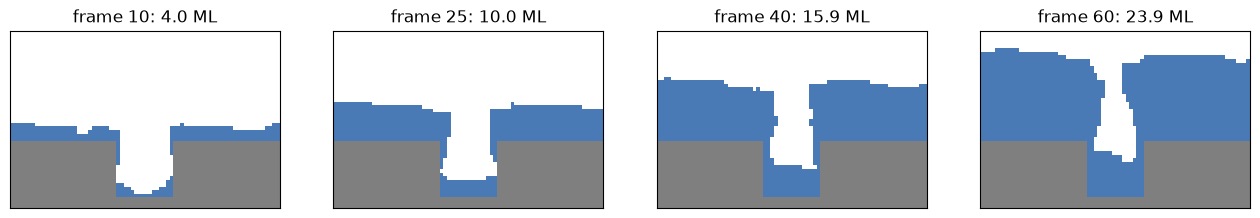

In [8]:
p = IDEAL["trench"]["settings"]
s = tr.TrenchSettings(trench_width=p["trench_width"], trench_depth=p["trench_depth"], n_monolayers=p["n_monolayers"],
                      temperature=p["temperature"], flux=p["flux"], seed=1)
rec_tr = record_trench(s, 60)
print("map shape (cropped rows, columns):", rec_tr["arrival"].shape, "| dtype:", rec_tr["arrival"].dtype)
print("final metrics:", final_metrics(rec_tr), "->", fab.spec_check("trench", final_metrics(rec_tr)))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, k in zip(axes, (10, 25, 40, 60)):
    ax.imshow(trench_frame(rec_tr, k), origin="lower", cmap=TRENCH_CMAP, vmin=0, vmax=3, interpolation="nearest")
    ax.set(title=f"frame {k}: {rec_tr['monolayers'][k]:.1f} ML", xticks=[], yticks=[])
plt.show()

Is the rebuilt frame really what the simulation had? Replay the same run step by step (the check in
`tests/test_recording.py::test_trench_frames_rebuild_exactly`) and compare every frame:

In [9]:
grid = tr.make_trench(s); e, h = s.thermal()
per_frame = int(round(s.n_monolayers * s.width / 60))
x0, _ = s.trench_x; lo = max(0, x0 - 30); rows, cols = rec_tr["arrival"].shape
ok = True
for k in range(1, 61):
    tr.deposit(grid, per_frame, e, h, s.seed * 1000 + k)
    ok &= np.array_equal(trench_frame(rec_tr, k), trench_image(grid, tr.find_voids(grid))[:rows, lo:lo + cols])
print("all 60 rebuilt frames identical to the real grids:", bool(ok))

all 60 rebuilt frames identical to the real grids: True


## 6. Yield: judging single wafers

A spec applies to **each** wafer, so the useful question is "what fraction of wafers made with this recipe pass?",
not "does the average pass?". `scripts/run_por_yield.py` runs 6 recipes × 30 seeds (`N_SEEDS = 30`) and saves every
wafer to `results/por_yield/data.csv`:

* thermal (100 ML, 200 columns, 60 frames, via `record_1d`): POR (375 K, 0.01 ML/s), 375 K at 1 ML/s, 450 K at 1 ML/s;
* trench (16 × 16, 24 ML, via `tr.grow` + `tr.measure`): POR (420 K, 1 ML/s), 460 K at 10 ML/s, 370 K at 1 ML/s.

The full run takes a couple of minutes, so here we repeat the script's loop for the first **5 seeds** of each recipe
and check that every wafer matches the saved row exactly. Then we analyse all 180 saved wafers.

In [10]:
RECIPES = [("thermal", "POR", 375.0, 0.01), ("thermal", "375 K, 1 ML/s", 375.0, 1.0), ("thermal", "450 K, 1 ML/s", 450.0, 1.0),
           ("trench", "POR", 420.0, 1.0), ("trench", "460 K, 10 ML/s", 460.0, 10.0), ("trench", "370 K, 1 ML/s", 370.0, 1.0)]
meta = json.load(open(os.path.join(RESULTS, "por_yield", "settings.json")))
print("saved recipes match the script's list:", [list(r) for r in RECIPES] == meta["settings"]["recipes"])

def one_wafer(module, temperature, flux, seed):
    # Same steps as scripts/run_por_yield.py::main for one wafer.
    if module == "thermal":
        eps, hops = thermal_parameters(temperature, 0.2, 0.8, flux, max_hops=1e4)
        m = final_metrics(record_1d("thermal", 200, IDEAL["thermal"]["settings"]["n_monolayers"], 60, seed, eps, hops))
    else:
        q = IDEAL["trench"]["settings"]
        st = tr.TrenchSettings(trench_width=q["trench_width"], trench_depth=q["trench_depth"],
                               n_monolayers=q["n_monolayers"], temperature=temperature, flux=flux, seed=seed)
        m = tr.measure(tr.grow(st), st)
    return {k: v for k, v in m.items() if k in ("rq", "trench_void_area", "step_coverage")} | {"result": fab.spec_check(module, m)}

saved = pd.read_csv(os.path.join(RESULTS, "por_yield", "data.csv"))
t0 = time.perf_counter()
mismatches = 0
for module, label, T, F in RECIPES:
    for seed in range(5):
        live = one_wafer(module, T, F, seed)
        row = saved[(saved.module == module) & (saved.recipe == label) & (saved.seed == seed)].iloc[0]
        same = live["result"] == row["result"] and all(np.isclose(v, row[k]) for k, v in live.items() if k != "result")
        mismatches += not same
print(f"30 wafers re-simulated in {time.perf_counter() - t0:.1f} s; mismatches with results/por_yield: {mismatches}")

saved recipes match the script's list: True


30 wafers re-simulated in 18.6 s; mismatches with results/por_yield: 0


### All 180 saved wafers

Pass counts per recipe, plus a rough uncertainty: with `n` wafers and a pass fraction `p`, the standard error of `p`
is `sqrt(p (1 - p) / n)` (binomial). With only 30 wafers, yields are uncertain by several percentage points.

In [11]:
summary = (saved.assign(passed=saved["result"] == "PASS").groupby(["module", "recipe"], sort=False)["passed"]
           .agg(passed="sum", wafers="count").reset_index())
summary["yield %"] = (100 * summary["passed"] / summary["wafers"]).round(0)
summary["± (1 s.e.) %"] = (100 * np.sqrt(summary["passed"] / summary["wafers"] * (1 - summary["passed"] / summary["wafers"]) / summary["wafers"])).round(0)
summary

,module,recipe,passed,wafers,yield %,± (1 s.e.) %
0,thermal,POR,30,30,100.0,0.0
1,thermal,"375 K, 1 ML/s",2,30,7.0,5.0
2,thermal,"450 K, 1 ML/s",24,30,80.0,7.0
3,trench,POR,24,30,80.0,7.0
4,trench,"460 K, 10 ML/s",16,30,53.0,9.0
5,trench,"370 K, 1 ML/s",9,30,30.0,8.0


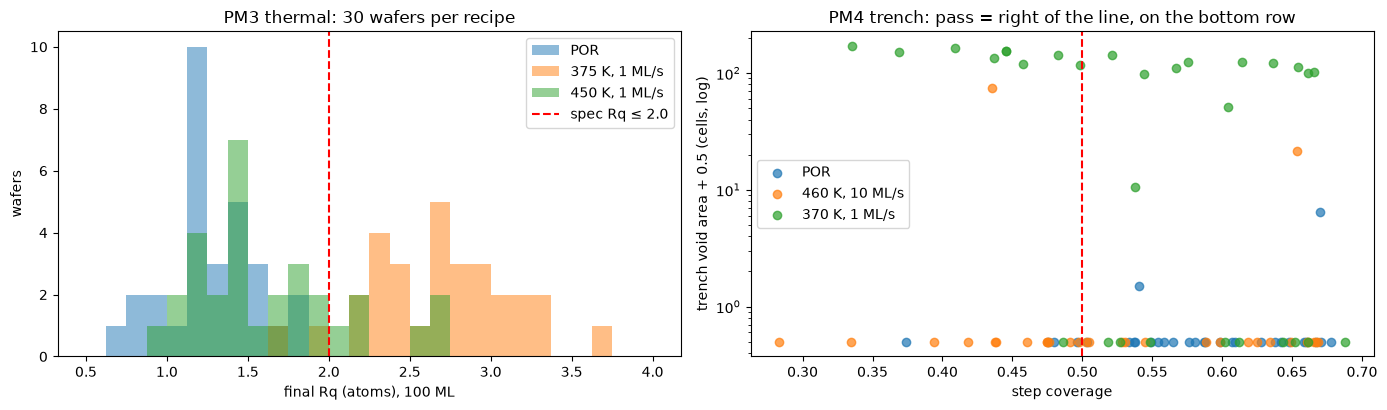

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
th_w = saved[saved.module == "thermal"]
for label, g in th_w.groupby("recipe", sort=False):
    axes[0].hist(g["rq"], bins=np.linspace(0.5, 4, 29), alpha=0.5, label=label)
axes[0].axvline(2.0, color="r", ls="--", label="spec Rq ≤ 2.0")
axes[0].set(xlabel="final Rq (atoms), 100 ML", ylabel="wafers", title="PM3 thermal: 30 wafers per recipe"); axes[0].legend()
tr_w = saved[saved.module == "trench"]
for label, g in tr_w.groupby("recipe", sort=False):
    axes[1].scatter(g["step_coverage"], g["trench_void_area"] + 0.5, alpha=0.7, label=label)
axes[1].axvline(0.5, color="r", ls="--"); axes[1].set_yscale("log")
axes[1].set(xlabel="step coverage", ylabel="trench void area + 0.5 (cells, log)", title="PM4 trench: pass = right of the line, on the bottom row")
axes[1].legend(); plt.tight_layout(); plt.show()

**What to notice** (saved data):
* **Thermal POR**: all 30 wafers pass. **375 K at 1 ML/s** (100× faster) passes only 2 of 30; **450 K at 1 ML/s**
  (same speed-up, but hotter) recovers to 24 of 30. Heat buys back speed, as notebook 3 predicted.
* **Trench POR**: 24 of 30 pass (80%). **460 K at 10 ML/s** passes 16 and **370 K at 1 ML/s** passes 9.
* The yield is a property of the **distribution** of wafers, which is why the process windows (averages over 4 or 8
  runs) are not enough to set a spec.

Which trench POR wafers failed, and why?

In [13]:
saved[(saved.module == "trench") & (saved.recipe == "POR") & (saved.result == "FAIL")][["seed", "step_coverage", "trench_void_area"]].round(3)

,seed,step_coverage,trench_void_area
90,0,0.475,0.0
93,3,0.480,0.0
96,6,0.670,6.0
97,7,0.496,0.0
106,16,0.374,0.0
113,23,0.540,1.0


## 7. How the yield study's numbers compare with the code comments

Comments and docstrings were written from earlier runs. Comparing them with the saved data is a good habit:

In [14]:
for label in ("POR", "375 K, 1 ML/s"):
    rq = th_w[th_w.recipe == label]["rq"]
    print(f"thermal {label:14s}: Rq min {rq.min():.2f}, max {rq.max():.2f}, 5th-95th percentile {np.percentile(rq, 5):.2f}-{np.percentile(rq, 95):.2f}")

thermal POR           : Rq min 0.74, max 1.84, 5th-95th percentile 0.80-1.75
thermal 375 K, 1 ML/s : Rq min 1.75, max 3.73, 5th-95th percentile 2.03-3.32


**What to notice:**
* `fab.py`'s comment says the thermal POR gave "Rq 0.95-1.86"; the saved data range is 0.74 to 1.84 (still always
  passing). For 375 K at 1 ML/s the comment says "5th-95th percentile Rq 1.87-3.29"; the saved data give about 2.03
  to 3.32. The conclusions (POR always passes; the fast recipe almost always fails) hold.
* `ideal.py` says the trench POR failures "have coverage just under 0.50 or a 1-6 cell void". The table above shows
  most do, but seed 16 failed with coverage 0.37, not "just under".
* The script's docstring says each recipe is run "exactly as the app does (60 frames)". That is true for the thermal
  module (`record_1d`), but for the trench it uses `tr.grow` (one `deposit` call for 24 × 128 = 3072 atoms), while the
  app uses `record_trench` (60 chunks of 51 atoms with seeds `seed * 1000 + k`). Same physics and statistics, but a
  given seed gives a **different wafer** in the app than in the yield table:

In [15]:
for seed in range(3):
    st = tr.TrenchSettings(trench_width=16, trench_depth=16, n_monolayers=24, temperature=420.0, flux=1.0, seed=seed)
    app_like = final_metrics(record_trench(st, 60))
    script_like = tr.measure(tr.grow(st), st)
    print(f"seed {seed}: app (record_trench) coverage {app_like['step_coverage']:.3f}, {app_like['monolayers']:.2f} ML | "
          f"yield script (grow) coverage {script_like['step_coverage']:.3f}, 24 ML")

seed 0: app (record_trench) coverage 0.643, 23.91 ML | yield script (grow) coverage 0.475, 24 ML


seed 1: app (record_trench) coverage 0.520, 23.91 ML | yield script (grow) coverage 0.667, 24 ML


seed 2: app (record_trench) coverage 0.487, 23.91 ML | yield script (grow) coverage 0.565, 24 ML


## 8. The app: from sidebar to browser player

Run it from the project root with `streamlit run app/streamlit_app.py` (Streamlit turns a Python script into a web
page; the `.streamlit/config.toml` theme applies when started from the root). The flow inside
`app/streamlit_app.py`, when you press **▶ Run wafer**:

```
sidebar widgets (module, temperature, log10 rate, trench size, thickness, frames, seed)
        |
        v
current_recipe()  ->  simulate(...)   [cached with st.cache_data]
                         |  trench: record_trench(TrenchSettings(...), n_frames)
                         |  1D:     thermal_parameters(...) then record_1d(...)
                         v
process_wafer():  final_metrics(rec) -> fab.spec_check -> wafer ID (fab.wafer_id) -> lot history row
                         |
                         v
player.wafer_payload(rec, ...)  ->  player.build_html([wafers], lot)  ->  components.html(...) in the page
```

**⇄ Compare with POR** does the same twice (your recipe and `IDEAL[module]` with the same seed and frame count) and
shows both side by side. The **Lot history** tab plots each wafer's metric against the spec. **⭐ Load POR** copies
`IDEAL[module]["settings"]` into the sliders (`por_settings`). The app's defaults are 375 K, 1 ML/s, a 12 × 16 trench,
24 ML, 60 frames and seed 42.

`app/player.py` packs a recording into JSON: arrays are converted to bytes and **base64**-encoded (a way to write
binary data as plain text), heights as 16-bit integers and trench maps as 8-bit. `build_html` pastes that JSON into
`app/fab_player.html` in place of the `__PAYLOAD__` placeholder, escaping `</` so the data can never close the
`<script>` tag early. The page's JavaScript then draws the chamber, readouts, in-situ/SEM views and the trace.

Let's build a two-wafer player page in memory (nothing is written) and decode it again.

In [16]:
w1 = player.wafer_payload(rec, wafer=fab.wafer_id("TF-0001", 1), label="POR", module="thermal",
                          recipe=fab.recipe_name("thermal", 375, 0.01, 100), status=fab.spec_check("thermal", final_metrics(rec)),
                          temperature=375, flux=0.01)
print("payload keys:", sorted(w1))
html = player.build_html([w1], "TF-0001")
print(f"player page size: {len(html) / 1024:.0f} KB")

import re
payload = json.loads(re.search(r"const P = (.*?);\n", html).group(1).replace("<\\/", "</"))
heights_back = np.frombuffer(base64.b64decode(payload["wafers"][0]["heights_b64"]), "<u2").reshape(rec["heights"].shape)
print("heights survive the round trip:", np.array_equal(heights_back, rec["heights"]))

payload keys: ['flux', 'heights_b64', 'kind', 'label', 'module', 'monolayers', 'n_columns', 'n_frames', 'rate_nm_min', 'recipe', 'rq', 'spec_limit', 'spec_text', 'status', 'temperature', 'wafer']
player page size: 59 KB
heights survive the round trip: True


Optional: save that page to your system's temporary folder (outside the project) and open it in a browser to see the
replay. Set `SAVE_REPLAY = True` to do it.

In [17]:
SAVE_REPLAY = False
if SAVE_REPLAY:
    path = os.path.join(tempfile.mkdtemp(), "TF-0001-W01_replay.html")
    with open(path, "w") as f:
        f.write(html)
    print("open in a browser:", path)
else:
    print("skipped (nothing written)")

skipped (nothing written)


The app is tested headlessly in `tests/test_app.py` with Streamlit's `AppTest`: it loads, runs one wafer per module,
loads the POR, compares recipe vs POR side by side, and keeps slider values when switching modules.
`tests/test_player.py` checks the base64 round trip and the `</script>` escaping.

## 9. Recap and exercises

### What we learned
* `ideal.py` stores one POR per model with its evidence; `fab.py` turns simulation numbers into fab language and
  applies single-wafer specs (PM3: Rq ≤ 2.0 at 100 ML; PM4: no trench void and step coverage ≥ 0.50).
* Yield is measured on individual wafers: thermal POR 30/30, trench POR 24/30; faster recipes pass fewer.
* `recording.py` stores runs compactly (heights per frame; arrival and void-start maps for trenches), and the replay
  rebuilds every frame exactly.
* The app chains sidebar → `simulate` (record) → `spec_check` → `player.build_html` → the browser player.

### Step → module/function → script map

| Step | Module / function | Script / test |
|---|---|---|
| POR settings and reasoning | `ideal.IDEAL` | `tests/test_ideal.py` |
| units, names, IDs | `fab.kelvin_to_celsius`, `rate_nm_per_min`, `thickness_nm`, `recipe_name`, `wafer_id` | `tests/test_recording.py::test_unit_conversions_and_specs` |
| pass/fail | `fab.SPECS`, `fab.spec_check` | same |
| record a run | `recording.record_1d`, `record_trench`, `final_metrics` | `tests/test_recording.py` |
| rebuild a frame | `recording.trench_frame` | `tests/test_recording.py::test_trench_frames_rebuild_exactly` |
| yield study | loop in `scripts/run_por_yield.py` | → `results/por_yield/` |
| player page | `app/player.py::wafer_payload`, `build_html`, `app/fab_player.html` | `tests/test_player.py` |
| the app | `app/streamlit_app.py` | `tests/test_app.py` |

### Try changing X and see Y
1. Tighten the PM3 spec to Rq ≤ 1.5 (`dict(fab.SPECS["thermal"], rq_max=1.5)`) and recount the saved thermal POR
   wafers that would pass.
2. In Part 6, loop the trench POR over seeds 0 to 29 with `record_trench` (app-style) instead of `tr.grow`. Is the
   pass rate close to 24/30?
3. Record a thermal wafer at 450 K and 1 ML/s with seed 0 and plot its Rq trace against the spec.
4. Change `n_frames` in `record_1d` from 60 to 20. Does the final Rq of a seed change? Why? (Hint: one seed is drawn
   per frame.)
5. Start the app, load the PM4 POR, set the width to 8 and press *Compare with POR*. Match what you see to notebook 4.

This is the last notebook. The technical write-up is `report/report.html`, the app tour `report/user_guide.html`, and
the plain-language overview `report/beginners_guide.html`.